# Task 1 — Part A: Local EDA & Preprocessing
Customer churn prediction (E-Commerce dataset). Everything here runs locally: load, EDA, clean, engineer features, split, and save the processed sets ready for S3.

## Setup — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")

print("libraries loaded — pandas", pd.__version__)

libraries loaded — pandas 3.0.5


## Load the Data
The workbook has two sheets: `Data Dict` (the column glossary — keep it so we can cite official definitions when engineering features) and `E Comm` (the actual data).

In [3]:
DATA_PATH = "data/E_Commerce_Dataset.xlsx"   # place this file next to the notebook

data_dict = pd.read_excel(DATA_PATH, sheet_name="Data Dict")
df        = pd.read_excel(DATA_PATH, sheet_name="E Comm")

print("data dictionary:", data_dict.shape)
print("main data:      ", df.shape)
df.head()

data dictionary: (21, 4)
main data:       (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


## Inspection of Dataset
Know the shape of the problem *before* touching anything. Three facts drive every later decision: the **class balance** (metric choice), the **missing values** (imputation), and confirming **CustomerID is unique** (so it's a pure identifier we can drop).

In [4]:
df.info()

print("\n--- missing values per column (only >0) ---")
mv = df.isnull().sum()
print(mv[mv > 0].sort_values(ascending=False))
print("total missing cells:", int(df.isnull().sum().sum()))

print("\n--- target balance (Churn) ---")
print(df["Churn"].value_counts())
print("churn rate: {:.2%}".format(df["Churn"].mean()))

print("\n--- unique values per column (cardinality) ---")
print(df.nunique())
print("\nduplicate CustomerIDs:", int(df["CustomerID"].duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

# Step 2 — Exploratory Data Analysis
Goal: understand *what drives churn* and *what needs cleaning*, so every preprocessing decision in Step 3 has evidence behind it. We define the column groups once and reuse them everywhere.

In [5]:
# column groups used throughout EDA and preprocessing
cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
            "PreferedOrderCat", "MaritalStatus"]

num_cols = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "NumberOfDeviceRegistered",
            "SatisfactionScore", "NumberOfAddress", "OrderAmountHikeFromlastYear",
            "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount", "CityTier"]

# Complain is already 0/1; CustomerID is an identifier; Churn is the target
print(len(cat_cols), "categorical +", len(num_cols), "numeric features")

5 categorical + 12 numeric features


### 2.1 — Target Distribution
Confirm the imbalance visually. ~17% churn means **accuracy is misleading** (predict "nobody churns" = 83% accuracy, 0 churners caught). This is why Part B scores on F1 / ROC-AUC / recall instead.

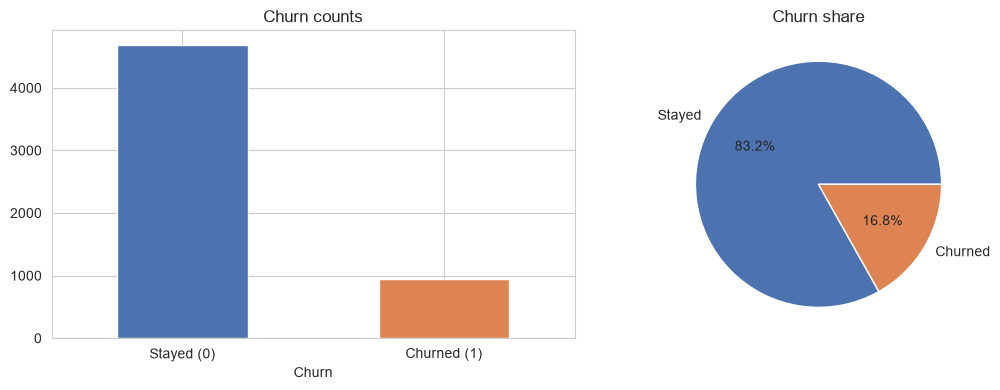

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Churn"].value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#dd8452"])
ax[0].set_title("Churn counts"); ax[0].set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)
df["Churn"].value_counts(normalize=True).plot.pie(
    ax=ax[1], autopct="%.1f%%", labels=["Stayed", "Churned"], colors=["#4c72b0", "#dd8452"])
ax[1].set_ylabel(""); ax[1].set_title("Churn share")
plt.tight_layout(); plt.show()

### 2.2 — Categorical Features: Raw Values
Print the raw categories first. This is where the data-quality problem surfaces: some columns have **the same real-world value under two different labels** (e.g. an abbreviation and its full name). A model treats each label as a separate category, so the churn signal gets split in two. We fix this in Step 3.

In [7]:
for c in cat_cols:
    print(f"{c:<22}: {df[c].unique().tolist()}")

PreferredLoginDevice  : ['Mobile Phone', 'Phone', 'Computer']
PreferredPaymentMode  : ['Debit Card', 'UPI', 'CC', 'Cash on Delivery', 'E wallet', 'COD', 'Credit Card']
Gender                : ['Female', 'Male']
PreferedOrderCat      : ['Laptop & Accessory', 'Mobile', 'Mobile Phone', 'Others', 'Fashion', 'Grocery']
MaritalStatus         : ['Single', 'Divorced', 'Married']


### 2.3 — Churn Rate by Category
Which categories churn most? Watch the duplicate labels: in `PreferedOrderCat`, *Mobile* and *Mobile Phone* churn at almost the same rate — strong evidence they're the same category split in two.

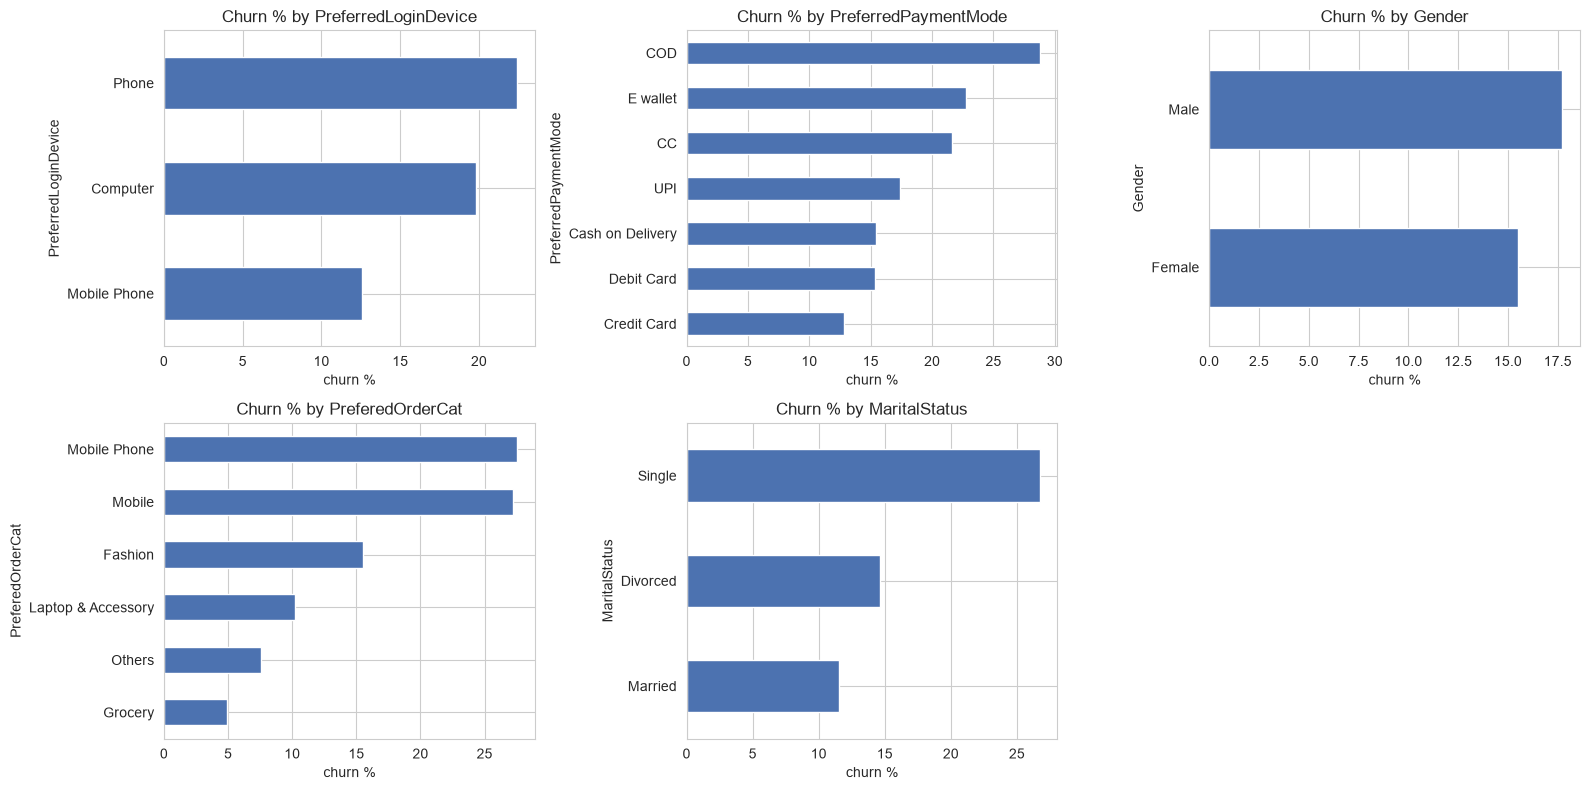

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    (df.groupby(c)["Churn"].mean() * 100).sort_values().plot.barh(ax=ax, color="#4c72b0")
    ax.set_title(f"Churn % by {c}"); ax.set_xlabel("churn %")
axes.ravel()[-1].axis("off")   # blank the 6th panel (only 5 categoricals)
plt.tight_layout(); plt.show()

### 2.4 — Numeric Features: Mean by Churn
A compact way to see which numbers separate churners from stayers. Big gaps = strong signals. `Tenure` stands out immediately (churners are much newer customers).

In [9]:
df.groupby("Churn")[num_cols].mean().T.round(2)

Churn,0,1
Tenure,11.50,3.38
WarehouseToHome,15.35,17.13
HourSpendOnApp,2.93,2.96
NumberOfDeviceRegistered,3.64,3.93
SatisfactionScore,3.00,3.39
NumberOfAddress,4.16,4.47
OrderAmountHikeFromlastYear,15.72,15.63
CouponUsed,1.76,1.72
OrderCount,3.05,2.82
DaySinceLastOrder,4.81,3.24


### 2.5 — Complaints vs Churn
`Complain` is binary (0/1) so it belongs with the categoricals conceptually. It's one of the strongest single signals in the data — worth calling out on its own.

churn % by complaint status:
Complain
0    10.9
1    31.7


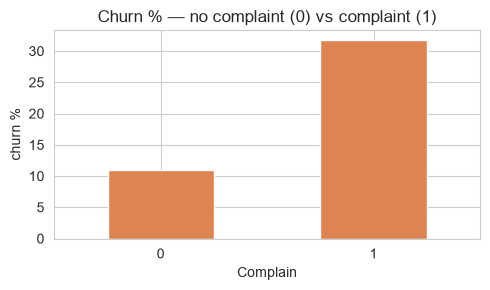

In [11]:
rate = (df.groupby("Complain")["Churn"].mean() * 100).round(1)
print("churn % by complaint status:")
print(rate.to_string())
rate.plot.bar(color="#dd8452", figsize=(5,3), rot=0,
              title="Churn % — no complaint (0) vs complaint (1)")
plt.ylabel("churn %"); plt.tight_layout(); plt.show()

### 2.6 — Numeric Correlations
Check for (a) features correlated with `Churn` and (b) features correlated with *each other* (redundancy). Tree models like XGBoost handle correlated features fine, but it's still useful to know.

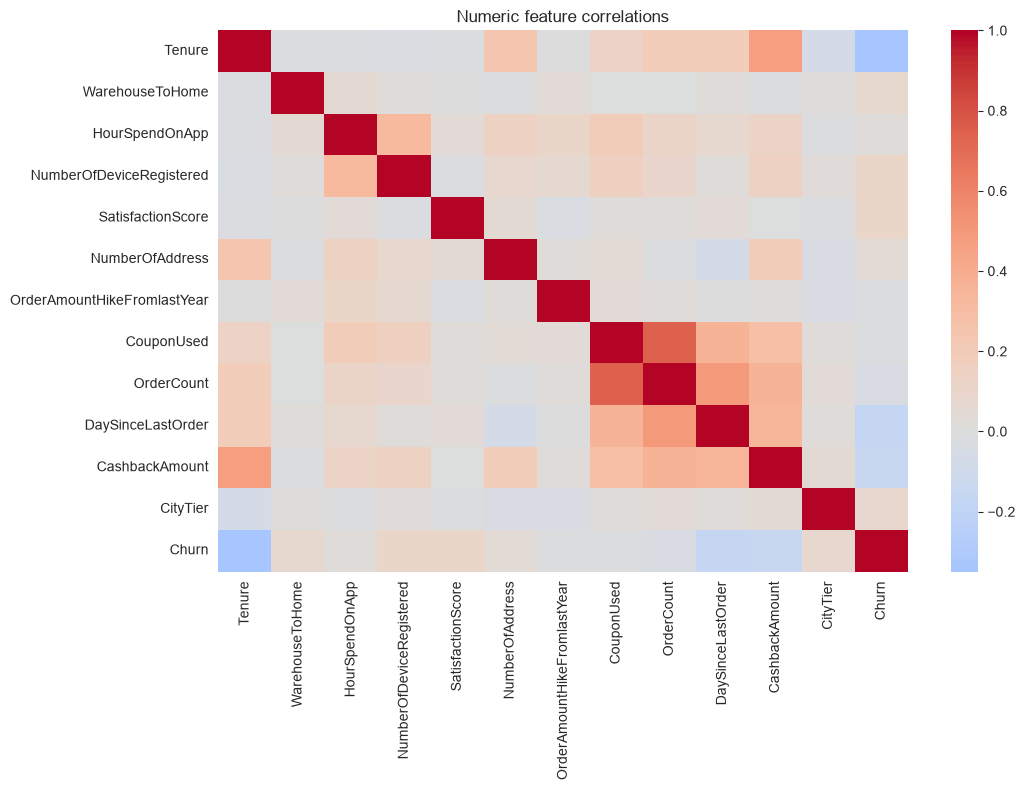

In [ ]:
plt.figure(figsize=(11, 8))
corr = df[num_cols + ["Churn"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Numeric feature correlations"); plt.tight_layout(); plt.show()
# more churn less tenure, more churn more days since last order, more churn less cashback amount
# CouponUsed, order count etc are reddish with eachother because customers who order more often use coupons more often, and have higher order counts

### 2.7 — Missing-Value Pattern
Which columns are missing and how badly. All seven are numeric and each is missing ~4–5% — small enough to impute rather than drop rows (dropping would throw away ~1,800 cells of otherwise-good data).

WarehouseToHome                4.5
HourSpendOnApp                 4.5
CouponUsed                     4.5
OrderCount                     4.6
Tenure                         4.7
OrderAmountHikeFromlastYear    4.7
DaySinceLastOrder              5.5


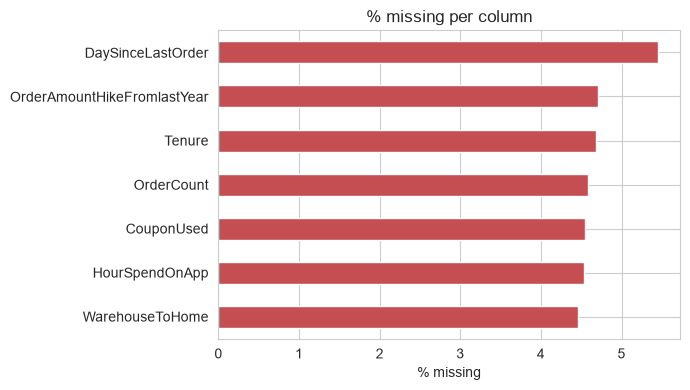

In [13]:
miss = (df.isnull().mean() * 100).loc[lambda s: s > 0].sort_values()
print(miss.round(1).to_string())
miss.plot.barh(color="#c44e52", figsize=(7,4), title="% missing per column")
plt.xlabel("% missing"); plt.tight_layout(); plt.show()

### 2.9 — EDA Findings (summary)
What the analysis tells us, and what each finding means for Step 3:

1. **Imbalanced target (16.84% churn).** → score on F1 / ROC-AUC / recall in Part B, not accuracy.
2. **Dirty categorical labels.** `PreferredLoginDevice` (*Phone* = *Mobile Phone*), `PreferredPaymentMode` (*CC* = *Credit Card*, *COD* = *Cash on Delivery*), and `PreferedOrderCat` (*Mobile* = *Mobile Phone*) each split one real value across two labels. → consolidate before encoding.
3. **Tenure is the top signal.** Churners average ~3 months vs ~11 for stayers. → keep as-is; strong predictor.
4. **Complaints matter a lot.** 31.7% churn with a complaint vs 10.9% without. → keep; strong predictor.
5. **Single customers churn most** (26.7% vs 11.5% married). → keep `MaritalStatus`.
6. **Seven numeric columns ~4–5% missing.** → impute (median), don't drop rows.
7. **Outliers** in `WarehouseToHome` (max 127) and `NumberOfAddress` (max 22). → review in Step 3.
8. **CustomerID is a unique identifier.** → drop before modeling (no predictive value, invites leakage).

# Step 3 — Feature Engineering & Preprocessing

## Fix #1 — Consolidate Duplicate Category Labels
EDA (2.2) showed three columns where one real value is split across two labels. A model treats each
label as a separate category, splitting the churn signal in two. We merge them to the descriptive name:
- PreferredLoginDevice: "Phone" -> "Mobile Phone"
- PreferredPaymentMode: "CC" -> "Credit Card", "COD" -> "Cash on Delivery"
- PreferedOrderCat: "Mobile" -> "Mobile Phone"

In [14]:
# Fix #1: consolidate duplicate category labels found in EDA
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({"CC": "Credit Card",
                                                                 "COD": "Cash on Delivery"})
df["PreferedOrderCat"]     = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

for c in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"{c}: {df[c].unique().tolist()}")

PreferredLoginDevice: ['Mobile Phone', 'Computer']
PreferredPaymentMode: ['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery', 'E wallet']
PreferedOrderCat: ['Laptop & Accessory', 'Mobile Phone', 'Others', 'Fashion', 'Grocery']


## Fix #2 — Drop the Identifier Column
CustomerID is a unique ID (5,630 unique values for 5,630 rows). It carries zero predictive signal —
it's just a label. Worse, leaving it in lets a tree model memorize individual customers (leakage),
inflating training scores while hurting real-world performance. We drop it before modeling.

In [15]:
# Fix #2: drop the identifier — no predictive value, and it invites leakage
df = df.drop(columns=["CustomerID"])

print("shape after drop:", df.shape)          # (5630, 19)
print("columns remaining:", df.columns.tolist())

shape after drop: (5630, 19)
columns remaining: ['Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']


## Fix #3 — Train / Validation / Test Split (stratified 70/15/15)
Split BEFORE any learned transform (imputation, scaling, encoding) so validation and test stay
truly unseen — otherwise statistics from val/test leak into training. We stratify on Churn so the
16.84% churn rate is preserved in every split (critical for imbalanced data).
- train (70%) -> fits the model
- validation (15%) -> scores each hyperparameter combo during HPO (Part B)
- test (15%) -> final evaluation + the "unseen data" for Batch Transform (Part B, step 6)

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

# Step 1: carve out the test set (15%), stratified to preserve the churn ratio
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)

# Step 2: split the remaining 85% into train (~70% of total) and validation (~15% of total)
#         0.1765 * 0.85 = 0.15, so validation ends up at 15% of the ORIGINAL data
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.1765, stratify=y_trainval, random_state=42)

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5}: {len(yy):4} rows | churn {yy.mean():.2%}")

train: 3940 rows | churn 16.85%
val  :  845 rows | churn 16.80%
test :  845 rows | churn 16.80%


## Fix #4 — Preprocessing Pipeline (ColumnTransformer)
One pipeline that: median-imputes then scales the numeric columns, and one-hot encodes the
categoricals. Complain is already 0/1 so it passes through untouched. We FIT on train only, then
apply (transform) to validation and test — this is what keeps val/test genuinely unseen.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "NumberOfDeviceRegistered",
            "SatisfactionScore", "NumberOfAddress", "OrderAmountHikeFromlastYear",
            "CouponUsed", "OrderCount", "DaySinceLastOrder", "CashbackAmount", "CityTier"]
cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
            "PreferedOrderCat", "MaritalStatus"]
# Complain is already 0/1 -> passthrough

# numeric: impute missing with median, THEN scale
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])

pre = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("bin", "passthrough", ["Complain"]),
], remainder="drop")

X_train_t = pre.fit_transform(X_train)   # LEARN the medians/averages/categories FROM train, then apply to train
X_val_t   = pre.transform(X_val)          # APPLY those same train-learned values to validation (learn nothing)
X_test_t  = pre.transform(X_test)         # APPLY those same train-learned values to test (learn nothing)


feat_names = pre.get_feature_names_out()
print("features:", X_train_t.shape[1])
print("train:", X_train_t.shape, "| val:", X_val_t.shape, "| test:", X_test_t.shape)

features: 30
train: (3940, 30) | val: (845, 30) | test: (845, 30)


## Fix #5 — Save the Preprocessed CSVs (SageMaker XGBoost format)
SageMaker's built-in XGBoost expects CSV with the label in the FIRST column and NO header row.
We save train + validation (both with label, for training/HPO) and a features-only test file
(no label, for Batch Transform in Part B). We also save the fitted preprocessor for reuse.

In [18]:
import pandas as pd, joblib

def to_sm_csv(X_arr, y_vals, path):
    out = pd.DataFrame(X_arr, columns=feat_names)
    out.insert(0, "Churn", y_vals.reset_index(drop=True).values)  # label FIRST
    out.to_csv(path, index=False, header=False)                   # NO header
    return out.shape

print("train.csv:      ", to_sm_csv(X_train_t, y_train, "train.csv"))
print("validation.csv: ", to_sm_csv(X_val_t,  y_val,  "validation.csv"))
print("test.csv:       ", to_sm_csv(X_test_t, y_test, "test.csv"))

# features-only test set (no label) — this is what Batch Transform scores in Part B
pd.DataFrame(X_test_t, columns=feat_names).to_csv("test_features.csv", index=False, header=False)
print("test_features.csv:", X_test_t.shape)

# save the FITTED preprocessor — its medians/means/category lists are now part of the model
joblib.dump(pre, "preprocessor.joblib")
print("saved preprocessor.joblib")

# sanity check: first column should be 0/1 labels, rest scaled decimals
pd.read_csv("train.csv", header=None).head(3).iloc[:, :6]

train.csv:       (3940, 31)
validation.csv:  (845, 31)
test.csv:        (845, 31)
test_features.csv: (845, 30)
saved preprocessor.joblib


,0,1,2,3,4,5
0,0,-0.013570,-0.431414,0.092373,0.303801,1.401718
1,0,0.229462,-0.672945,-1.329305,-0.666195,-0.043276
2,0,-1.107218,0.776239,1.514051,0.303801,-1.488271
